# Checkpoint 5 | Agrupamento de vinhos com K-means
**FIAP · Tecnologia em Inteligência Artificial · 2º semestre**  
**Disciplina:** Machine Learning & Modelling  
**Escopo:** Parte 2 do enunciado, com estatística descritiva de apoio.

Este notebook segue o roteiro de `Clusterizacao_I.ipynb` (Aula 08): compreender os dados,
preparar as variáveis, ajustar K-means, comparar Elbow e Silhouette e interpretar os grupos.
As etapas de leitura, limpeza e estatística descritiva também se apoiam no case iFood das aulas.

Os nomes e RMs dos integrantes não foram fornecidos; a identificação deve constar no PDF
do grupo exigido pelo enunciado. Este notebook não substitui esse documento nem a apresentação oral.

**Como executar:** mantenha `wines.csv` na mesma pasta deste notebook, instale as dependências
do `requirements.txt` e execute todas as células em ordem. Os dados são locais; não há download
ou instalação de pacotes durante a análise.

## 1. Introdução: problema e solução proposta (item a)
Queremos identificar grupos de vinhos com **perfis químicos semelhantes**, sem fornecer ao
algoritmo a classe conhecida de cada vinho. Isso pode apoiar a exploração e a descrição do conjunto.
Não estamos prevendo qualidade, preço ou preferência do consumidor.

A solução proposta usa **K-means**, que atribui cada observação ao centróide mais próximo e busca
reduzir a soma das distâncias euclidianas ao quadrado dentro dos grupos (inércia ou WCSS).
Usaremos as 13 medidas químicas padronizadas, pois suas escalas são diferentes.

| Requisito da Parte 2 | Onde é atendido |
|---|---|
| a) Introdução — 0,5 ponto | Seção 1 |
| b) Pré-processamento — 2,0 pontos | Seções 3 a 5 |
| c) Ajuste de K-means — 2,0 pontos | Seções 6 e 7 |
| d) Elbow e Silhouette Score — 2,0 pontos | Seção 6 |
| e) Características de cada grupo — 3,5 pontos | Seções 8 e 9 |

A estatística descritiva aqui auxilia a modelagem e a interpretação. As tabelas de frequência
e os cálculos probabilísticos da Parte 1 não fazem parte deste recorte.

## 2. Bibliotecas e reprodutibilidade
Fixamos a semente em `42` e `n_init=20`. As 20 inicializações diminuem a dependência de uma
única escolha inicial dos centróides; a melhor solução em termos de inércia é mantida.
Isso não garante um ótimo global nem a existência de grupos naturais.

In [1]:
# Limitar threads antes dos imports numéricos evita excesso de paralelismo nesta base pequena.
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

from pathlib import Path
import hashlib
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples

RANDOM_STATE = 42
N_INIT = 20
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

print("Python:", platform.python_version())
for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    print(f"{package}: {importlib.metadata.version(package)}")

Python: 3.12.14
numpy: 2.5.4
pandas: 3.0.6
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2


## 3. Origem, variáveis e verificação dos dados (item b)
Usamos a versão CSV do [GitHub Gist indicado no enunciado](https://gist.github.com/tijptjik/9408623),
salva no repositório como `wines.csv` (na fonte, o nome é `wine.csv`).
A revisão consultada é `b237fa5848349a14a14e5d4107dc7897c21951f5`.

Segundo a [UCI, origem do Wine Dataset](https://archive.ics.uci.edu/dataset/109/wine), o conjunto
contém 178 amostras, 13 medidas químicas e vinhos de três cultivares de uma mesma região da Itália.
**Essa informação contextual não será usada para fixar K.** O número de grupos será avaliado pelas métricas.

| Coluna | Significado / decisão |
|---|---|
| `Wine` | Classe/cultivar conhecido. Excluída das entradas. |
| `Alcohol` | Teor alcoólico. |
| `Malic.acid` | Ácido málico; medida relacionada à acidez. |
| `Ash` | Cinzas. |
| `Acl` | Alcalinidade das cinzas. |
| `Mg` | Magnésio. |
| `Phenols` | Fenóis totais. |
| `Flavanoids` | Flavonoides. |
| `Nonflavanoid.phenols` | Fenóis não flavonoides. |
| `Proanth` | Proantocianidinas. |
| `Color.int` | Intensidade de cor. |
| `Hue` | Tonalidade. |
| `OD` | Razão OD280/OD315 de vinhos diluídos. |
| `Proline` | Prolina. |

As comparações usarão a escala numérica original do arquivo, sem inventar unidades não documentadas.
`Acl` não é acidez do vinho: é **alcalinidade das cinzas**.

In [2]:
# Caminho relativo: funciona ao abrir o notebook a partir da pasta do repositório.
arquivo = Path("wines.csv")
if not arquivo.is_file():
    raise FileNotFoundError("Mantenha wines.csv na pasta do notebook e execute a partir dessa pasta.")

df = pd.read_csv(arquivo)
print(f"Dimensões: {df.shape[0]} vinhos e {df.shape[1]} colunas")
print("SHA256 do CSV:", hashlib.sha256(arquivo.read_bytes()).hexdigest())
display(df.head())

Dimensões: 178 vinhos e 14 colunas
SHA256 do CSV: f295f06d18e62351ee3c0ea3b508558d07e1d72d7fb5bb848fe066d7c1b9884e


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.230,1.710,2.430,15.600,127,2.800,3.060,0.280,2.290,5.640,1.040,3.920,1065
1,1,13.200,1.780,2.140,11.200,100,2.650,2.760,0.260,1.280,4.380,1.050,3.400,1050
2,1,13.160,2.360,2.670,18.600,101,2.800,3.240,0.300,2.810,5.680,1.030,3.170,1185
3,1,14.370,1.950,2.500,16.800,113,3.850,3.490,0.240,2.180,7.800,0.860,3.450,1480
4,1,13.240,2.590,2.870,21.000,118,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735


In [3]:
# Diagnóstico explícito antes de decidir sobre limpeza ou imputação.
diagnostico = pd.DataFrame({
    "Tipo": df.dtypes.astype(str),
    "Nulos": df.isna().sum(),
    "Valores distintos": df.nunique(),
})
display(diagnostico)
print("Linhas completamente duplicadas:", int(df.duplicated().sum()))

# Wine é uma classe conhecida, não uma característica química.
X = df.drop(columns=["Wine"]).copy()
assert X.shape == (178, 13), "Confira se foi usada a versão correta do dataset."
assert X.select_dtypes(include="number").shape[1] == X.shape[1]
assert not X.isna().any().any(), "Há nulos: revisar a limpeza antes da modelagem."
assert np.isfinite(X.to_numpy()).all(), "Há valores não finitos nas características."
assert (X.nunique() > 1).all(), "Há uma variável constante; revisar a seleção."

print("Entradas do modelo:", X.columns.tolist())
print("Classe Wine excluída. Quantidade de medidas químicas:", X.shape[1])

,Tipo,Nulos,Valores distintos
Wine,int64,0,3
Alcohol,float64,0,126
Malic.acid,float64,0,133
Ash,float64,0,79
Acl,float64,0,63
Mg,int64,0,53
Phenols,float64,0,97
Flavanoids,float64,0,132
Nonflavanoid.phenols,float64,0,39
Proanth,float64,0,101


Linhas completamente duplicadas: 0
Entradas do modelo: ['Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']
Classe Wine excluída. Quantidade de medidas químicas: 13


**Decisão de limpeza:** nesta versão não há nulos nem linhas completamente duplicadas.
Não é necessário imputar ou excluir observações por esses motivos. As 13 medidas são numéricas,
não constantes e pertinentes ao perfil químico; serão mantidas. A coluna `Wine` permanece apenas
no dataframe original e não participa da padronização, do K-means ou da escolha de K.
Se o arquivo for substituído e surgirem nulos, a execução interrompe para que a limpeza seja revista.

## 4. Estatística descritiva de apoio
Antes de calcular distâncias, examinamos média, mediana, desvio padrão, mínimo, máximo e quartis.
O desvio padrão mostra dispersão; quartis e boxplots ajudam a observar assimetria e valores extremos.
As medidas abaixo são calculadas **antes da padronização**.

In [4]:
# describe fornece média, desvio amostral, extremos e quartis de cada medida química.
resumo = X.describe().T.rename(columns={
    "count": "N", "mean": "Média", "std": "Desvio padrão",
    "min": "Mínimo", "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máximo",
})
resumo["IQR"] = resumo["Q3"] - resumo["Q1"]
display(resumo)

,N,Média,Desvio padrão,Mínimo,Q1,Mediana,Q3,Máximo,IQR
Alcohol,178.000,13.001,0.812,11.030,12.362,13.050,13.678,14.830,1.315
Malic.acid,178.000,2.336,1.117,0.740,1.603,1.865,3.083,5.800,1.480
Ash,178.000,2.367,0.274,1.360,2.210,2.360,2.558,3.230,0.348
Acl,178.000,19.495,3.340,10.600,17.200,19.500,21.500,30.000,4.300
Mg,178.000,99.742,14.282,70.000,88.000,98.000,107.000,162.000,19.000
Phenols,178.000,2.295,0.626,0.980,1.742,2.355,2.800,3.880,1.057
Flavanoids,178.000,2.029,0.999,0.340,1.205,2.135,2.875,5.080,1.670
Nonflavanoid.phenols,178.000,0.362,0.124,0.130,0.270,0.340,0.438,0.660,0.167
Proanth,178.000,1.591,0.572,0.410,1.250,1.555,1.950,3.580,0.700
Color.int,178.000,5.058,2.318,1.280,3.220,4.690,6.200,13.000,2.980


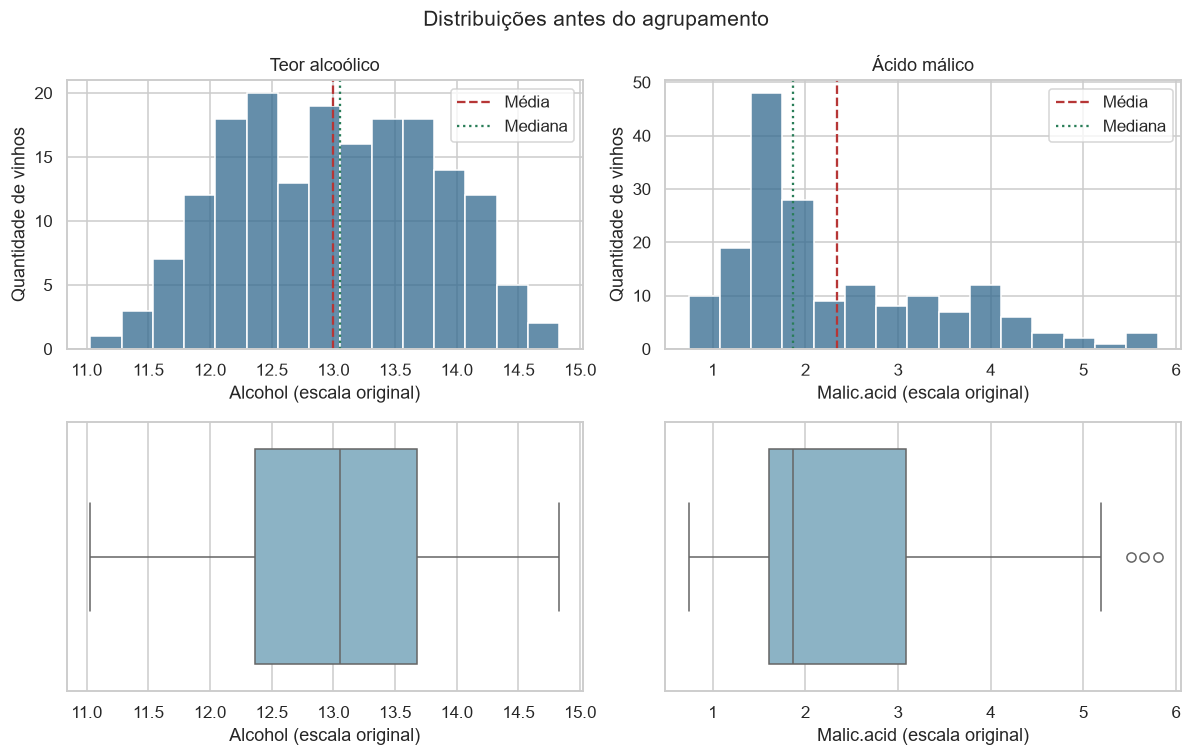

In [5]:
# Foco em duas variáveis que respondem diretamente às perguntas do enunciado.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, titulo, top, bottom in zip(
    ["Alcohol", "Malic.acid"], ["Teor alcoólico", "Ácido málico"], axes[0], axes[1]
):
    sns.histplot(data=X, x=col, bins=15, ax=top, color="#31688e")
    top.axvline(X[col].mean(), color="#b63636", linestyle="--", label="Média")
    top.axvline(X[col].median(), color="#287d57", linestyle=":", label="Mediana")
    top.set(title=titulo, xlabel=f"{col} (escala original)", ylabel="Quantidade de vinhos")
    top.legend()
    sns.boxplot(data=X, x=col, ax=bottom, color="#82b7cf")
    bottom.set(xlabel=f"{col} (escala original)")
fig.suptitle("Distribuições antes do agrupamento", fontsize=14)
fig.tight_layout()
plt.show()

In [6]:
# Regra exploratória de Tukey: sinalizar extremos não significa provar erro no dado.
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
fora_iqr = (X.lt(q1 - 1.5 * iqr) | X.gt(q3 + 1.5 * iqr)).sum()
display(fora_iqr.rename("Valores fora de 1,5 IQR").to_frame().T)

display(Markdown(
    f"A média de `Alcohol` é **{X['Alcohol'].mean():.2f}** e a mediana é "
    f"**{X['Alcohol'].median():.2f}**. Para `Malic.acid`, são "
    f"**{X['Malic.acid'].mean():.2f}** e **{X['Malic.acid'].median():.2f}**, respectivamente. "
    "Em Alcohol, a proximidade entre média e mediana sugere menor assimetria nesse resumo. "
    "Em Malic.acid, a média maior que a mediana, o histograma e os valores altos no boxplot "
    "sugerem uma cauda à direita. Não assumimos normalidade. "
    "As escalas diferem bastante: a prolina assume valores numericamente muito maiores que "
    "várias outras medidas. Sem escalonamento, essa diferença pode dominar as distâncias."
))

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
"Valores fora de 1,5 IQR",0,3,3,4,4,0,0,0,2,4,1,0,0


A média de `Alcohol` é **13.00** e a mediana é **13.05**. Para `Malic.acid`, são **2.34** e **1.87**, respectivamente. Em Alcohol, a proximidade entre média e mediana sugere menor assimetria nesse resumo. Em Malic.acid, a média maior que a mediana, o histograma e os valores altos no boxplot sugerem uma cauda à direita. Não assumimos normalidade. As escalas diferem bastante: a prolina assume valores numericamente muito maiores que várias outras medidas. Sem escalonamento, essa diferença pode dominar as distâncias.

**Valores extremos:** mantemos as observações sinalizadas pela regra de 1,5 IQR, pois não há
evidência de erro de medição. Removê-las automaticamente pode apagar diferenças químicas reais.
K-means e StandardScaler são sensíveis a extremos; essa é uma limitação desta análise e pode
motivar uma análise de sensibilidade futura. Aqui a decisão é conservar a base original.

## 5. Padronização (item b)
Aplicamos `StandardScaler` a cada uma das 13 características:

\[
z = \frac{x - \mu}{\sigma}
\]

Assim, cada variável passa a ter média aproximadamente zero e desvio padrão populacional
aproximadamente um (`ddof=0`). O `describe` anterior usa desvio **amostral** (`ddof=1`), por isso
essas duas convenções não devem ser confundidas.

A padronização equilibra as escalas, mas **não transforma as distribuições em normais**,
não elimina outliers e não remove correlações. Mantemos as 13 medidas para seguir a proposta
do enunciado. O agrupamento será exploratório sobre a base inteira; não há avaliação de previsão
em novas amostras nem necessidade de um split supervisionado para este objetivo.

In [7]:
# O dataframe X fica intacto, permitindo interpretar os resultados nas unidades originais.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

checagem_escala = pd.DataFrame({
    "Média padronizada": X_scaled.mean(axis=0),
    "Desvio padrão (ddof=0)": X_scaled.std(axis=0, ddof=0),
}, index=X.columns)
display(checagem_escala.round(6))
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0, ddof=0), 1, atol=1e-10)

,Média padronizada,Desvio padrão (ddof=0)
Alcohol,-0.000,1.000
Malic.acid,-0.000,1.000
Ash,-0.000,1.000
Acl,-0.000,1.000
Mg,-0.000,1.000
Phenols,0.000,1.000
Flavanoids,-0.000,1.000
Nonflavanoid.phenols,0.000,1.000
Proanth,-0.000,1.000
Color.int,0.000,1.000


## 6. Ajuste de K-means e escolha de K (itens c e d)
Comparamos **K de 1 a 10** usando as mesmas entradas padronizadas e os mesmos parâmetros.

- **Elbow:** representa a inércia em função de K. A inércia diminui ao aumentar os grupos;
  procuramos uma região em que os ganhos passam a ser menores. O menor valor de inércia
  sozinho não escolhe K, pois favoreceria mais grupos.
- **Silhouette Score:** compara coesão e separação, usando distâncias **entre amostras**.
  Para uma amostra, $a$ é a distância média às outras amostras do mesmo grupo e $b$ é a menor
  distância média a outro grupo. A silhueta é $(b-a)/\max(a,b)$, e o score é a média das silhuetas.
  Varia de -1 a 1; valores próximos de zero indicam sobreposição. Não é definida para K=1.

**Critério de seleção:** usar o maior Silhouette entre K=2 e K=10 e confrontar a escolha com
o gráfico Elbow. Isso identifica a melhor alternativa **entre as configurações testadas**;
não prova um número universal de grupos. O rótulo `Wine` não é consultado nessa escolha.

In [8]:
avaliacoes = []
for k in range(1, 11):
    modelo = KMeans(
        n_clusters=k, init="k-means++", n_init=N_INIT,
        random_state=RANDOM_STATE, max_iter=300,
    )
    labels_k = modelo.fit_predict(X_scaled)
    # Silhouette exige pelo menos dois grupos.
    score = silhouette_score(X_scaled, labels_k) if k >= 2 else np.nan
    avaliacoes.append({"K": k, "Inercia": modelo.inertia_, "Silhouette": score})

resultados_k = pd.DataFrame(avaliacoes)
resultados_k["Redução da inércia (%)"] = -resultados_k["Inercia"].pct_change() * 100
validos = resultados_k.dropna(subset=["Silhouette"])
k_escolhido = int(validos.loc[validos["Silhouette"].idxmax(), "K"])
display(resultados_k.round(4))
print("K com maior Silhouette:", k_escolhido)

,K,Inercia,Silhouette,Redução da inércia (%)
0,1,2314.000,NaN,NaN
1,2,1658.759,0.259,28.316
2,3,1277.928,0.285,22.959
3,4,1175.352,0.259,8.027
4,5,1107.007,0.232,5.815
5,6,1046.002,0.237,5.511
6,7,981.595,0.204,6.157
7,8,935.201,0.157,4.726
8,9,889.893,0.150,4.845
9,10,845.895,0.144,4.944


K com maior Silhouette: 3


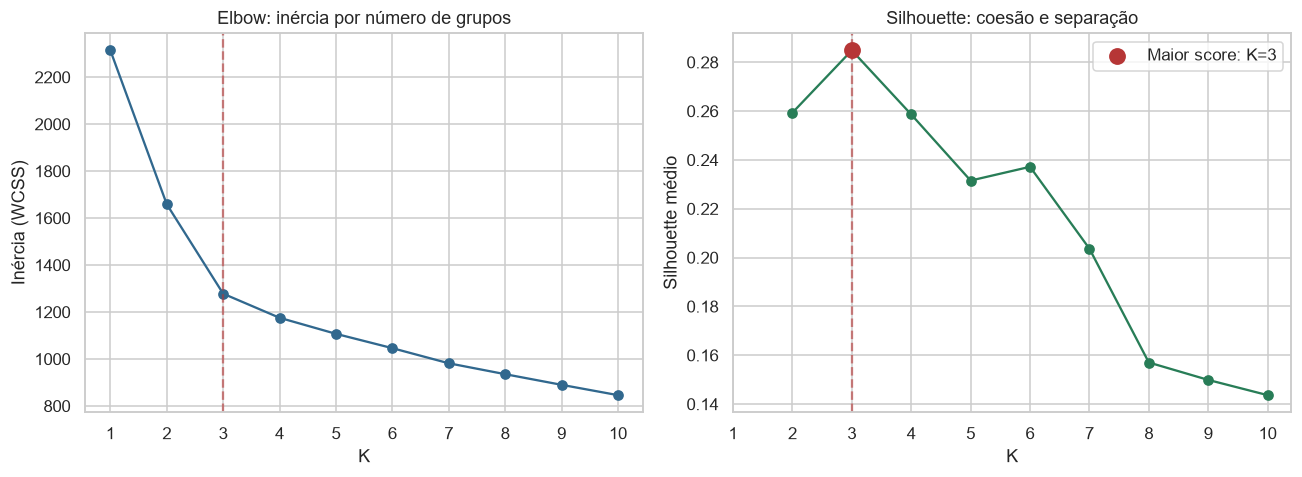

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(resultados_k.K, resultados_k.Inercia, "o-", color="#31688e")
axes[0].set(title="Elbow: inércia por número de grupos", xlabel="K", ylabel="Inércia (WCSS)")
axes[1].plot(validos.K, validos.Silhouette, "o-", color="#287d57")
melhor_score = float(validos.loc[validos.K == k_escolhido, "Silhouette"].iloc[0])
axes[1].scatter(k_escolhido, melhor_score, color="#b63636", s=100, zorder=5,
                label=f"Maior score: K={k_escolhido}")
axes[1].set(title="Silhouette: coesão e separação", xlabel="K", ylabel="Silhouette médio")
axes[1].legend()
for ax in axes:
    ax.axvline(k_escolhido, color="#b63636", linestyle="--", alpha=0.6)
    ax.set_xticks(range(1, 11))
fig.tight_layout()
plt.show()

In [10]:
# Quantificar a região do cotovelo auxilia a leitura visual, sem simular um teste formal.
reducoes = resultados_k.set_index("K")["Redução da inércia (%)"]
display(Markdown(
    f"**Escolha: K = {k_escolhido}**, com Silhouette **{melhor_score:.4f}**. "
    f"A redução de inércia é de **{reducoes.loc[2]:.1f}%** ao passar de 1 para 2 grupos, "
    f"**{reducoes.loc[3]:.1f}%** de 2 para 3 e **{reducoes.loc[4]:.1f}%** de 3 para 4. "
    "A mudança de inclinação após K=3 sugere um cotovelo nessa região: adicionar o quarto "
    "grupo produz um ganho proporcional menor do que adicionar o terceiro. "
    "Nesta execução, o Elbow apoia a escolha de três grupos pelo Silhouette. "
    "O cotovelo é uma indicação visual, "
    "não uma prova de separação perfeita. A decisão operacional segue o maior Silhouette "
    "dentre os valores testados, com a inércia como evidência complementar."
))

**Escolha: K = 3**, com Silhouette **0.2849**. A redução de inércia é de **28.3%** ao passar de 1 para 2 grupos, **23.0%** de 2 para 3 e **8.0%** de 3 para 4. A mudança de inclinação após K=3 sugere um cotovelo nessa região: adicionar o quarto grupo produz um ganho proporcional menor do que adicionar o terceiro. Nesta execução, o Elbow apoia a escolha de três grupos pelo Silhouette. O cotovelo é uma indicação visual, não uma prova de separação perfeita. A decisão operacional segue o maior Silhouette dentre os valores testados, com a inércia como evidência complementar.

## 7. Modelo final e diagnóstico das silhuetas (item c)
Reajustamos K-means com o K selecionado, mantendo os parâmetros usados na comparação.
Para facilitar a leitura, os grupos são apresentados como 1, 2, ..., K. Esses números são
identificadores arbitrários; não representam classe verdadeira, qualidade ou ordem de mérito.

In [11]:
modelo_final = KMeans(
    n_clusters=k_escolhido, init="k-means++", n_init=N_INIT,
    random_state=RANDOM_STATE, max_iter=300,
)
rotulos = modelo_final.fit_predict(X_scaled)
silhouette_final = silhouette_score(X_scaled, rotulos)
silhuetas = silhouette_samples(X_scaled, rotulos)

# Retornar às medidas originais: o agrupamento é padronizado, a interpretação é química.
df_grupos = X.copy()
df_grupos["Grupo"] = rotulos + 1
ordem_grupos = list(range(1, k_escolhido + 1))
cores = dict(zip(ordem_grupos, sns.color_palette("colorblind", k_escolhido)))

tamanhos = df_grupos.groupby("Grupo").size().rename("Vinhos").to_frame()
tamanhos["Participação (%)"] = tamanhos.Vinhos / len(df_grupos) * 100
diagnostico_silhueta = pd.DataFrame({"Grupo": rotulos + 1, "Silhueta": silhuetas})
tamanhos["Silhueta média"] = diagnostico_silhueta.groupby("Grupo").Silhueta.mean()
tamanhos["Silhuetas negativas"] = diagnostico_silhueta.groupby("Grupo").Silhueta.apply(lambda s: int((s < 0).sum()))
display(tamanhos)
print(f"Inércia final: {modelo_final.inertia_:.4f}")
print(f"Silhouette final: {silhouette_final:.4f}")

,Vinhos,Participação (%),Silhueta média,Silhuetas negativas
Grupo,,,,
1,65,36.517,0.177,7
2,51,28.652,0.351,0
3,62,34.831,0.343,0


Inércia final: 1277.9285
Silhouette final: 0.2849


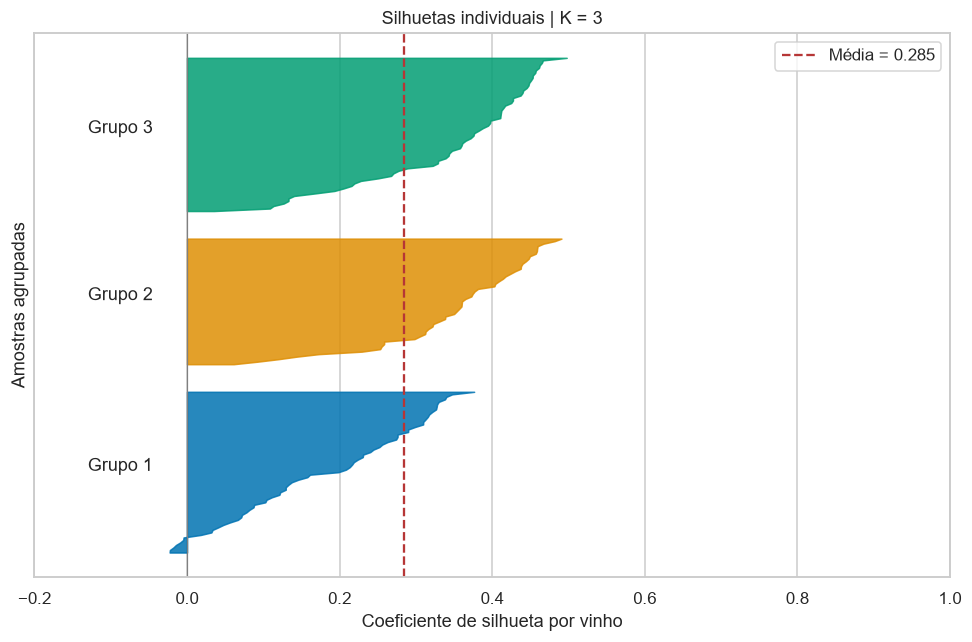

In [12]:
# Cada faixa contém as silhuetas individuais de um grupo, ordenadas para facilitar a leitura.
fig, ax = plt.subplots(figsize=(9, 6))
inicio = 10
for grupo in ordem_grupos:
    valores = np.sort(silhuetas[rotulos == grupo - 1])
    fim = inicio + len(valores)
    ax.fill_betweenx(np.arange(inicio, fim), 0, valores, color=cores[grupo], alpha=0.85)
    ax.text(-0.13, (inicio + fim) / 2, f"Grupo {grupo}")
    inicio = fim + 10
ax.axvline(silhouette_final, color="#b63636", linestyle="--", label=f"Média = {silhouette_final:.3f}")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlim=(-0.2, 1), yticks=[], xlabel="Coeficiente de silhueta por vinho",
       ylabel="Amostras agrupadas", title=f"Silhuetas individuais | K = {k_escolhido}")
ax.legend()
fig.tight_layout()
plt.show()

In [13]:
negativas = int((silhuetas < 0).sum())
display(Markdown(
    f"O score médio é **{silhouette_final:.4f}**, e **{negativas} de {len(X)} vinhos** "
    f"({100 * negativas / len(X):.1f}%) têm silhueta negativa. "
    "Esses casos merecem cautela: em média, estão mais próximos de outro grupo do que do próprio. "
    "O resultado oferece uma segmentação exploratória, com sobreposição entre perfis; "
    "não devemos descrevê-la como uma separação perfeita."
))

O score médio é **0.2849**, e **7 de 178 vinhos** (3.9%) têm silhueta negativa. Esses casos merecem cautela: em média, estão mais próximos de outro grupo do que do próprio. O resultado oferece uma segmentação exploratória, com sobreposição entre perfis; não devemos descrevê-la como uma separação perfeita.

## 8. Comparação e interpretação dos grupos (item e)
Agora respondemos às perguntas do enunciado com médias, medianas, dispersão e extremos
**nas escalas originais**. Usar apenas centróides padronizados para falar de álcool ou ácido
málico confundiria as unidades com os escores z.

### 8.1 Tamanho e perfis médios

In [14]:
perfil = df_grupos.groupby("Grupo")[X.columns].mean()
display(perfil.T.rename_axis("Característica"))

# Os centróides voltam à escala original e devem concordar com as médias dos grupos.
centroides_originais = pd.DataFrame(
    scaler.inverse_transform(modelo_final.cluster_centers_),
    columns=X.columns, index=pd.Index(ordem_grupos, name="Grupo"),
)
assert np.allclose(centroides_originais.to_numpy(), perfil.to_numpy(), atol=1e-8)
print("Centróides na escala original conferidos com as médias dos grupos.")

Grupo,1,2,3
Característica,,,
Alcohol,12.251,13.134,13.677
Malic.acid,1.897,3.307,1.998
Ash,2.231,2.418,2.466
Acl,20.063,21.241,17.463
Mg,92.738,98.667,107.968
Phenols,2.248,1.684,2.848
Flavanoids,2.050,0.819,3.003
Nonflavanoid.phenols,0.358,0.452,0.292
Proanth,1.624,1.146,1.922


Centróides na escala original conferidos com as médias dos grupos.


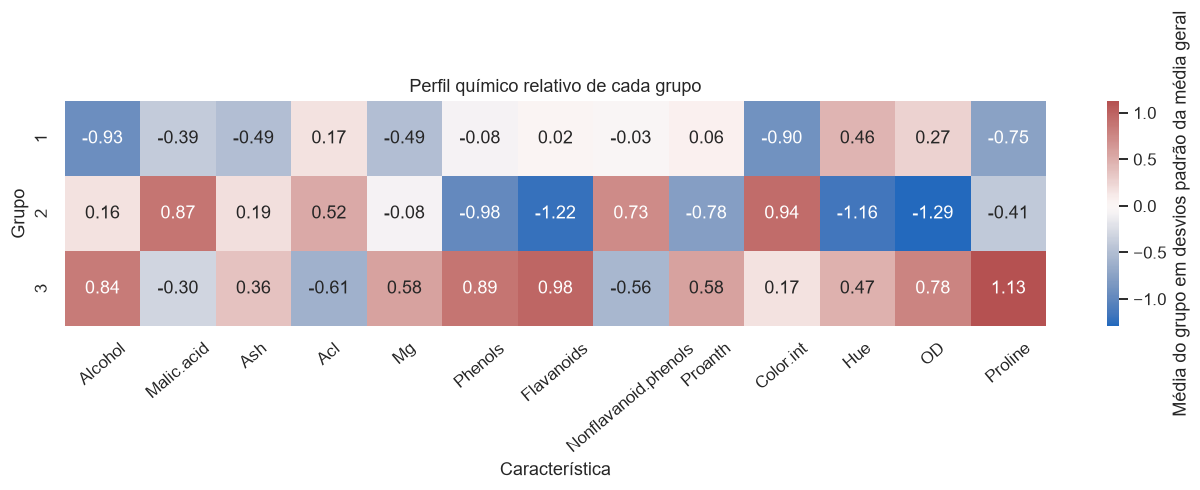

In [15]:
# Heatmap de médias em escores z para comparar variáveis com escalas diferentes.
perfil_z = pd.DataFrame(X_scaled, columns=X.columns).assign(Grupo=rotulos + 1).groupby("Grupo").mean()
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="vlag", center=0,
            cbar_kws={"label": "Média do grupo em desvios padrão da média geral"}, ax=ax)
ax.set(title="Perfil químico relativo de cada grupo", xlabel="Característica", ylabel="Grupo")
ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
plt.show()

**Como ler:** valores positivos no heatmap indicam média do grupo acima da média geral;
negativos indicam abaixo. O mapa mostra contrastes relativos, sem atribuir qualidade aos vinhos.
O valor zero representa a média geral após padronização.

### 8.2 Teor alcoólico e ácido málico

Alcohol                            Malic.acid                         
         mean median   std    min    max       mean median   std   min   max
Grupo                                                                       
1      12.251 12.250 0.533 11.030 13.860      1.897  1.610 1.012 0.740 5.800
2      13.134 13.110 0.522 12.200 14.340      3.307  3.270 1.093 1.240 5.650
3      13.677 13.735 0.559 11.560 14.830      1.998  1.765 0.676 1.350 4.040

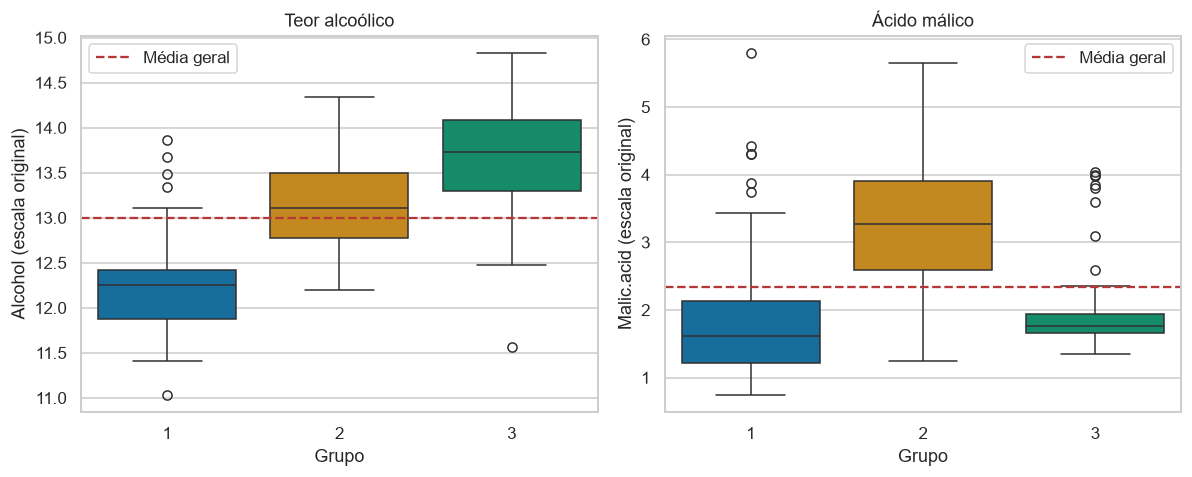

In [16]:
estatisticas_alcool_acido = df_grupos.groupby("Grupo")[["Alcohol", "Malic.acid"]].agg(
    ["mean", "median", "std", "min", "max"]
)
display(estatisticas_alcool_acido)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, titulo in zip(axes, ["Alcohol", "Malic.acid"], ["Teor alcoólico", "Ácido málico"]):
    sns.boxplot(data=df_grupos, x="Grupo", y=col, hue="Grupo", order=ordem_grupos,
                palette=cores, legend=False, ax=ax)
    ax.axhline(X[col].mean(), color="#b63636", linestyle="--", label="Média geral")
    ax.set(title=titulo, ylabel=f"{col} (escala original)")
    ax.legend()
fig.tight_layout()
plt.show()

In [17]:
grupo_alcool = int(perfil["Alcohol"].idxmax())
grupo_acido = int(perfil["Malic.acid"].idxmax())
display(Markdown(
    f"**Maior teor alcoólico médio:** Grupo {grupo_alcool}, com "
    f"**{perfil.loc[grupo_alcool, 'Alcohol']:.2f}** na escala do dataset. "
    f"**Maior concentração média de ácido málico:** Grupo {grupo_acido}, com "
    f"**{perfil.loc[grupo_acido, 'Malic.acid']:.2f}**. "
    "Essa segunda resposta operacionaliza a pergunta sobre vinhos mais ácidos usando "
    "a medida disponível. Ela não comprova maior acidez total, menor pH ou sensação mais ácida. "
    "Os boxplots mostram a dispersão e eventual sobreposição; médias de grupos não descrevem "
    "igualmente todos os vinhos."
))

**Maior teor alcoólico médio:** Grupo 3, com **13.68** na escala do dataset. **Maior concentração média de ácido málico:** Grupo 2, com **3.31**. Essa segunda resposta operacionaliza a pergunta sobre vinhos mais ácidos usando a medida disponível. Ela não comprova maior acidez total, menor pH ou sensação mais ácida. Os boxplots mostram a dispersão e eventual sobreposição; médias de grupos não descrevem igualmente todos os vinhos.

### 8.3 Visualização em duas características
O modelo utiliza **13 dimensões**. O gráfico abaixo mostra apenas álcool e ácido málico,
na escala original, com a cor definida pelo agrupamento encontrado. Uma sobreposição nesse
plano não resume sozinha a separação no espaço completo.

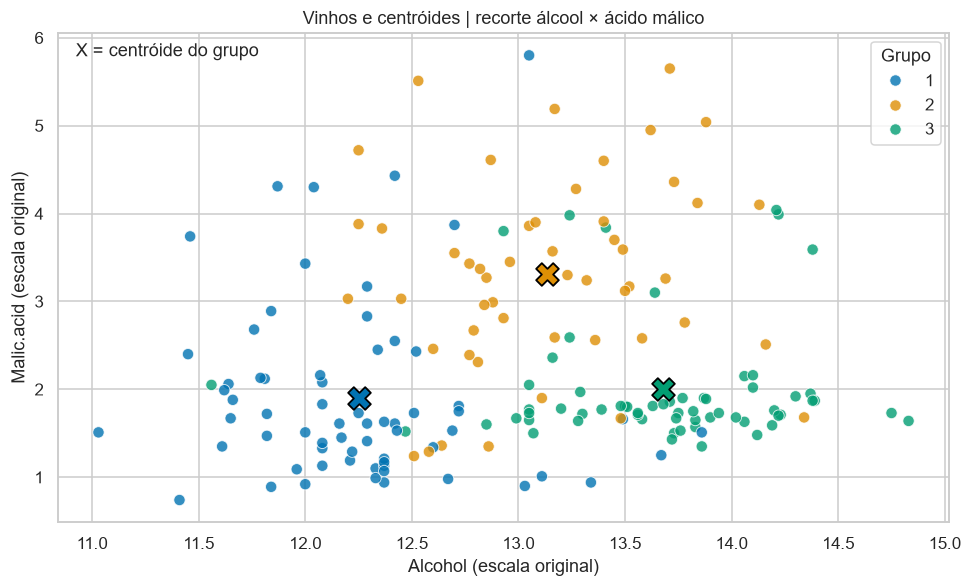

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=df_grupos, x="Alcohol", y="Malic.acid", hue="Grupo",
                palette=cores, s=55, alpha=0.8, ax=ax)
for grupo in ordem_grupos:
    ax.scatter(centroides_originais.loc[grupo, "Alcohol"], centroides_originais.loc[grupo, "Malic.acid"],
               marker="X", s=220, c=[cores[grupo]], edgecolors="black", linewidths=1.2, zorder=5)
ax.set(title="Vinhos e centróides | recorte álcool × ácido málico",
       xlabel="Alcohol (escala original)", ylabel="Malic.acid (escala original)")
ax.text(0.02, 0.98, "X = centróide do grupo", transform=ax.transAxes, va="top")
fig.tight_layout()
plt.show()

### 8.4 Características que diferenciam cada grupo
As descrições abaixo são calculadas a partir das tabelas, incluindo álcool, ácido málico,
cinzas e flavonoides. Os dois maiores contrastes positivos e negativos no heatmap ajudam a
complementar os perfis. Eles expressam distância da média geral, não importância causal.

In [19]:
for grupo in ordem_grupos:
    media = perfil.loc[grupo]
    amostras = df_grupos[df_grupos.Grupo == grupo]
    altos = perfil_z.loc[grupo].nlargest(2)
    baixos = perfil_z.loc[grupo].nsmallest(2)
    contrastes_altos = "; ".join(f"{nome}: {valor:+.2f} DP" for nome, valor in altos.items())
    contrastes_baixos = "; ".join(f"{nome}: {valor:+.2f} DP" for nome, valor in baixos.items())
    display(Markdown(
        f"**Grupo {grupo} — {len(amostras)} vinhos ({100 * len(amostras) / len(X):.1f}% da base)**\n\n"
        f"- Álcool: média **{media['Alcohol']:.2f}**, mediana "
        f"**{amostras.Alcohol.median():.2f}**, intervalo observado "
        f"**{amostras.Alcohol.min():.2f}–{amostras.Alcohol.max():.2f}**.\n"
        f"- Ácido málico: média **{media['Malic.acid']:.2f}**; cinzas: "
        f"**{media['Ash']:.2f}**; flavonoides: **{media['Flavanoids']:.2f}**.\n"
        f"- Maiores valores relativos: {contrastes_altos}.\n"
        f"- Menores valores relativos: {contrastes_baixos}.\n"
    ))

**Grupo 1 — 65 vinhos (36.5% da base)**

- Álcool: média **12.25**, mediana **12.25**, intervalo observado **11.03–13.86**.
- Ácido málico: média **1.90**; cinzas: **2.23**; flavonoides: **2.05**.
- Maiores valores relativos: Hue: +0.46 DP; OD: +0.27 DP.
- Menores valores relativos: Alcohol: -0.93 DP; Color.int: -0.90 DP.


**Grupo 2 — 51 vinhos (28.7% da base)**

- Álcool: média **13.13**, mediana **13.11**, intervalo observado **12.20–14.34**.
- Ácido málico: média **3.31**; cinzas: **2.42**; flavonoides: **0.82**.
- Maiores valores relativos: Color.int: +0.94 DP; Malic.acid: +0.87 DP.
- Menores valores relativos: OD: -1.29 DP; Flavanoids: -1.22 DP.


**Grupo 3 — 62 vinhos (34.8% da base)**

- Álcool: média **13.68**, mediana **13.73**, intervalo observado **11.56–14.83**.
- Ácido málico: média **2.00**; cinzas: **2.47**; flavonoides: **3.00**.
- Maiores valores relativos: Proline: +1.13 DP; Flavanoids: +0.98 DP.
- Menores valores relativos: Acl: -0.61 DP; Nonflavanoid.phenols: -0.56 DP.


## 9. Conclusão e limitações

In [20]:
display(Markdown(
    f"A solução agrupou os **{len(X)} vinhos em {k_escolhido} grupos**, usando as "
    f"**{X.shape[1]} características químicas padronizadas**, sem a coluna de classe `Wine`. "
    f"Entre K=2 e K=10, a melhor silhueta média foi **{silhouette_final:.4f}**. "
    "A comparação com Elbow permite avaliar o ganho de compactação ao adicionar grupos.\n\n"
    f"O **Grupo {grupo_alcool}** apresentou maior teor alcoólico médio, enquanto o "
    f"**Grupo {grupo_acido}** apresentou maior ácido málico médio. "
    "Cinzas, fenóis, flavonoides, cor, OD e prolina complementam a diferenciação dos perfis, "
    "como mostrado nas tabelas e no heatmap.\n\n"
    "O resultado atende ao objetivo exploratório de descrever vinhos semelhantes nesta base. "
    "A silhueta e os casos negativos mostram que existem fronteiras e sobreposição; "
    "não há evidência de que cada grupo corresponda exatamente a uma cultivar."
))

A solução agrupou os **178 vinhos em 3 grupos**, usando as **13 características químicas padronizadas**, sem a coluna de classe `Wine`. Entre K=2 e K=10, a melhor silhueta média foi **0.2849**. A comparação com Elbow permite avaliar o ganho de compactação ao adicionar grupos.

O **Grupo 3** apresentou maior teor alcoólico médio, enquanto o **Grupo 2** apresentou maior ácido málico médio. Cinzas, fenóis, flavonoides, cor, OD e prolina complementam a diferenciação dos perfis, como mostrado nas tabelas e no heatmap.

O resultado atende ao objetivo exploratório de descrever vinhos semelhantes nesta base. A silhueta e os casos negativos mostram que existem fronteiras e sobreposição; não há evidência de que cada grupo corresponda exatamente a uma cultivar.

**Limitações e alcance**

- K-means busca grupos compactos sob distância euclidiana e pode representar mal formas,
  densidades ou tamanhos muito diferentes. Sempre retorna uma partição, mesmo sem grupos naturais.
- O resultado depende da padronização, das variáveis e da inicialização. A semente e as versões
  registradas favorecem a reprodução; 20 inicializações não garantem o ótimo global.
- Mantivemos possíveis extremos e todas as medidas químicas. Variáveis correlacionadas podem
  dar peso maior a aspectos semelhantes do perfil; não foi feita análise de sensibilidade.
- A escolha foi avaliada em K=2 a K=10 nesta base. Não é garantia de generalização para outros vinhos.
- Ácido málico não substitui acidez total ou pH. Nenhuma conclusão sobre sabor, qualidade ou preço
  pode ser derivada diretamente deste agrupamento.

**Para explicar oralmente:** apresentar o objetivo não supervisionado, justificar a retirada de
`Wine` e a padronização, ler Elbow e Silhouette, comparar álcool/ácido málico e reconhecer as limitações.

## 10. Referências

- Enunciado **Checkpoint 5**, Parte 2 — Machine Learning & Modelling, fornecido pelo aluno.
- Material do professor: **Aula 08 — Clusterizacao_I.ipynb**, de 01/10/2026, e análise exploratória
  do **Case iFood — Parte 1**, contidos no arquivo `Sem2.zip` fornecido pelo aluno.
- [CSV do GitHub Gist indicado no enunciado](https://gist.github.com/tijptjik/9408623).
- [CSV na revisão usada](https://gist.githubusercontent.com/tijptjik/9408623/raw/b237fa5848349a14a14e5d4107dc7897c21951f5/wine.csv).
- [UCI Machine Learning Repository — Wine](https://archive.ics.uci.edu/dataset/109/wine).
- [scikit-learn — KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).
- [scikit-learn — StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [scikit-learn — silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

**Nota metodológica:** a definição de silhueta usada aqui segue a documentação oficial:
distâncias médias entre amostras, não distâncias a centróides. O notebook é uma adaptação
ao problema de vinhos; não reproduz automaticamente os resultados dos dados sintéticos da aula.